# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

1. Check out the data set `heart_failure` and appropriately clean it.

In [9]:
import pandas as pd


df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")
print("Shape:", df.shape)
print(df.isna().sum())
print("Data types", df.dtypes)
df = df.dropna()
df.head()
# The dataset has 299 rows and 13 columns with 0 missing values in any column.
# The variables are numeric (int64 or float64)
#The binary columns  like anaemia, diabetes, sex, and smoking are coded binary 0 or 1.
#made sure with the dropna 

Shape: (299, 13)
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Data types age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'anaemia'}>,
        <Axes: title={'center': 'creatinine_phosphokinase'}>,
        <Axes: title={'center': 'diabetes'}>],
       [<Axes: title={'center': 'ejection_fraction'}>,
        <Axes: title={'center': 'high_blood_pressure'}>,
        <Axes: title={'center': 'platelets'}>,
        <Axes: title={'center': 'serum_creatinine'}>],
       [<Axes: title={'center': 'serum_sodium'}>,
        <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'smoking'}>,
        <Axes: title={'center': 'time'}>],
       [<Axes: title={'center': 'DEATH_EVENT'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

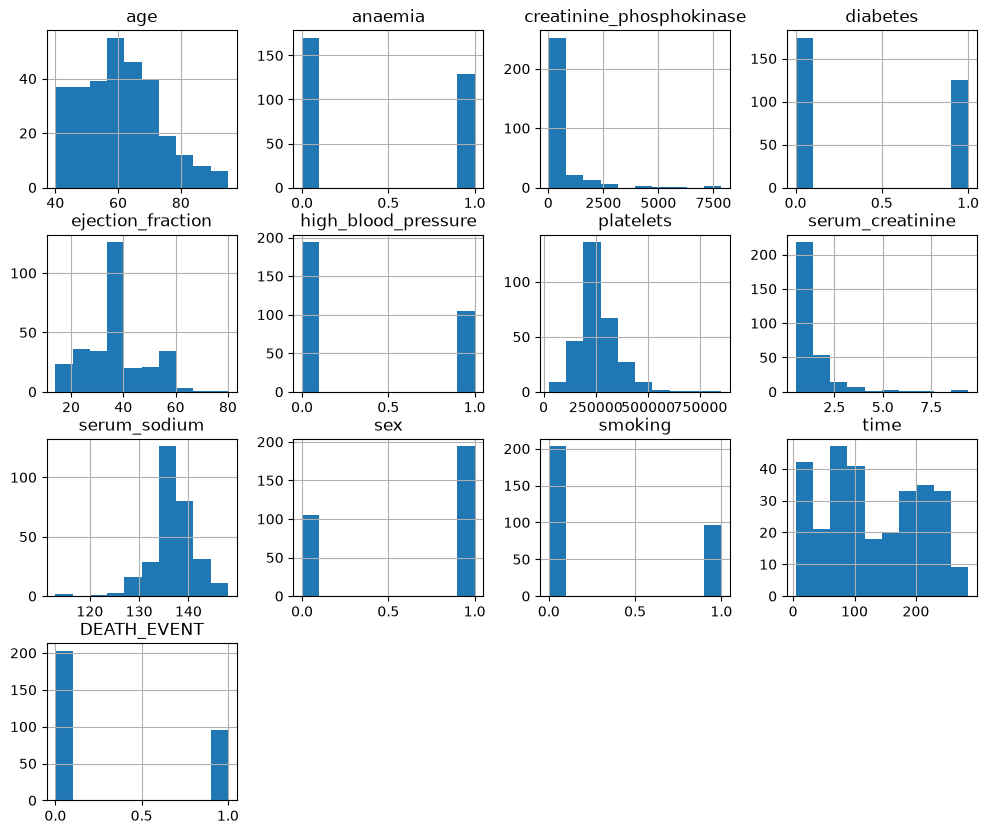

In [11]:
df.hist(figsize=(12, 10))
#for fun just wanted to see)

2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.

In [13]:
from sklearn.model_selection import train_test_split

eval_x_raw = df.drop(columns=['anaemia'])
eval_y = df['anaemia']

(x_train, x_test, y_train, y_test,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=100)

In [14]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

tree_model = DecisionTreeRegressor(max_depth=3, random_state=100)
tree_model.fit(x_train, y_train)

tree_preds_base = tree_model.predict(x_test)

print("Tree R-squared - train:", round(tree_model.score(x_train, y_train), 4))
print("Tree R-squared - test:", round(tree_model.score(x_test, y_test), 4))
print("Tree RMSE - train:", round(root_mean_squared_error(y_train, tree_model.predict(x_train)), 4))
print("Tree RMSE - test:", round(root_mean_squared_error(y_test, tree_preds_base), 4))

Tree R-squared - train: 0.1892
Tree R-squared - test: -0.0629
Tree RMSE - train: 0.4473
Tree RMSE - test: 0.5012


In [15]:
from sklearn.linear_model import LinearRegression

lin_model = LinearRegression()
lin_model.fit(x_train, y_train)

lin_preds_base = lin_model.predict(x_test)

print("Linear R-squared - train:", round(lin_model.score(x_train, y_train), 4))
print("Linear R-squared - test:", round(lin_model.score(x_test, y_test), 4))
print("Linear RMSE - train:", round(root_mean_squared_error(y_train, lin_model.predict(x_train)), 4))
print("Linear RMSE - test:", round(root_mean_squared_error(y_test, lin_preds_base), 4))

Linear R-squared - train: 0.08
Linear R-squared - test: 0.0152
Linear RMSE - train: 0.4765
Linear RMSE - test: 0.4825


In [16]:
# Using random_state=100 for the 80/20 split and predicting anaemia
#both models have low test R-squared values because anaemia has a weak relationship with the other variables in the dataset.
# On the test set, the linear model performs slightly better test R-squared = 0.0152 and test RMSE = 0.4825
# than the decision tree test R-squared = -0.0629 and test RMSE = 0.5012
# Also the decision tree also shows a larger gap between train and test
# showing slight overfitting on the training data. 


3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
#not the best with forwards loops so if u guys want to change it to a loop than be my guest

In [24]:
#101
(x_train_101, x_test_101, y_train_101, y_test_101,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=101)

tree_101 = DecisionTreeRegressor(max_depth=3, random_state=100)
tree_101.fit(x_train_101, y_train_101)
tree_preds_101 = tree_101.predict(x_test)

lin_101 = LinearRegression()
lin_101.fit(x_train_101, y_train_101)
lin_preds_101 = lin_101.predict(x_test)

print("Tree 101 R-squared - test:", round(tree_101.score(x_test_101, y_test_101), 4))
print("Tree 101 RMSE - test:", round(root_mean_squared_error(y_test_101, tree_101.predict(x_test_101)), 4))
print("Linear 101 R-squared - test:", round(lin_101.score(x_test_101, y_test_101), 4))
print("Linear 101 RMSE - test:", round(root_mean_squared_error(y_test_101, lin_101.predict(x_test_101)), 4))
print("Linear 101 coefs:", lin_101.coef_.round(4))

Tree 101 R-squared - test: -0.3251
Tree 101 RMSE - test: 0.5743
Linear 101 R-squared - test: 0.0458
Linear 101 RMSE - test: 0.4873
Linear 101 coefs: [ 0.0016 -0.0001 -0.0084  0.0012 -0.0447  0.      0.0212  0.0082 -0.0729
 -0.0347 -0.0009  0.0042]


In [25]:
#102
(x_train_102, x_test_102, y_train_102, y_test_102,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=102)

tree_102 = DecisionTreeRegressor(max_depth=3, random_state=100)
tree_102.fit(x_train_102, y_train_102)
tree_preds_102 = tree_102.predict(x_test)

lin_102 = LinearRegression()
lin_102.fit(x_train_102, y_train_102)
lin_preds_102 = lin_102.predict(x_test)

print("Tree 102 R-squared - test:", round(tree_102.score(x_test_102, y_test_102), 4))
print("Tree 102 RMSE - test:", round(root_mean_squared_error(y_test_102, tree_102.predict(x_test_102)), 4))
print("Linear 102 R-squared - test:", round(lin_102.score(x_test_102, y_test_102), 4))
print("Linear 102 RMSE - test:", round(root_mean_squared_error(y_test_102, lin_102.predict(x_test_102)), 4))
print("Linear 102 coefs:", lin_102.coef_.round(4))

Tree 102 R-squared - test: -0.1446
Tree 102 RMSE - test: 0.5349
Linear 102 R-squared - test: -0.026
Linear 102 RMSE - test: 0.5065
Linear 102 coefs: [ 8.000e-04 -1.000e-04 -4.730e-02 -5.000e-04 -1.950e-02 -0.000e+00
  1.630e-02  1.410e-02 -1.740e-02 -1.363e-01 -8.000e-04  3.180e-02]


In [26]:
# Seed 103
(x_train_103, x_test_103, y_train_103, y_test_103,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=103)

tree_103 = DecisionTreeRegressor(max_depth=3, random_state=100)
tree_103.fit(x_train_103, y_train_103)
tree_preds_103 = tree_103.predict(x_test)

lin_103 = LinearRegression()
lin_103.fit(x_train_103, y_train_103)
lin_preds_103 = lin_103.predict(x_test)

print("Tree 103 R-squared - test:", round(tree_103.score(x_test_103, y_test_103), 4))
print("Tree 103 RMSE - test:", round(root_mean_squared_error(y_test_103, tree_103.predict(x_test_103)), 4))
print("Linear 103 R-squared - test:", round(lin_103.score(x_test_103, y_test_103), 4))
print("Linear 103 RMSE - test:", round(root_mean_squared_error(y_test_103, lin_103.predict(x_test_103)), 4))
print("Linear 103 coefs:", lin_103.coef_.round(4))

Tree 103 R-squared - test: -0.175
Tree 103 RMSE - test: 0.5417
Linear 103 R-squared - test: 0.0642
Linear 103 RMSE - test: 0.4834
Linear 103 coefs: [ 0.0016 -0.0001 -0.065   0.0015 -0.0174 -0.      0.02    0.0099 -0.0404
 -0.0553 -0.0008  0.0199]


In [27]:
(x_train_104, x_test_104, y_train_104, y_test_104,) = train_test_split(eval_x_raw, eval_y, test_size=0.20, random_state=104)

tree_104 = DecisionTreeRegressor(max_depth=3, random_state=100)
tree_104.fit(x_train_104, y_train_104)
tree_preds_104 = tree_104.predict(x_test)

lin_104 = LinearRegression()
lin_104.fit(x_train_104, y_train_104)
lin_preds_104 = lin_104.predict(x_test)

print("Tree 104 R-squared - test:", round(tree_104.score(x_test_104, y_test_104), 4))
print("Tree 104 RMSE - test:", round(root_mean_squared_error(y_test_104, tree_104.predict(x_test_104)), 4))
print("Linear 104 R-squared - test:", round(lin_104.score(x_test_104, y_test_104), 4))
print("Linear 104 RMSE - test:", round(root_mean_squared_error(y_test_104, lin_104.predict(x_test_104)), 4))
print("Linear 104 coefs:", lin_104.coef_.round(4))

Tree 104 R-squared - test: -0.3371
Tree 104 RMSE - test: 0.573
Linear 104 R-squared - test: -0.0525
Linear 104 RMSE - test: 0.5084
Linear 104 coefs: [ 1.000e-04 -1.000e-04  1.440e-02  1.300e-03  4.000e-03 -0.000e+00
  1.390e-02  1.330e-02 -6.890e-02 -1.143e-01 -1.200e-03  1.280e-02]


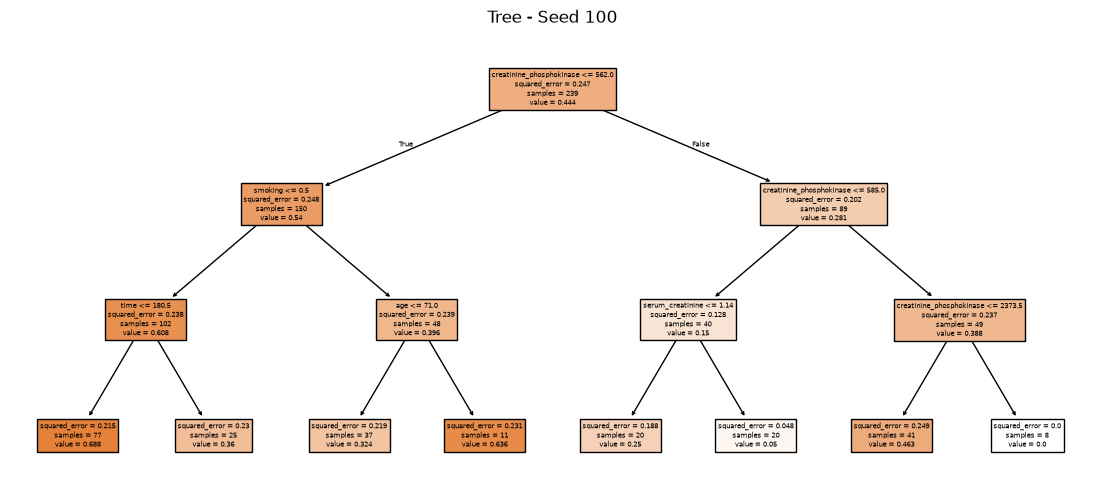

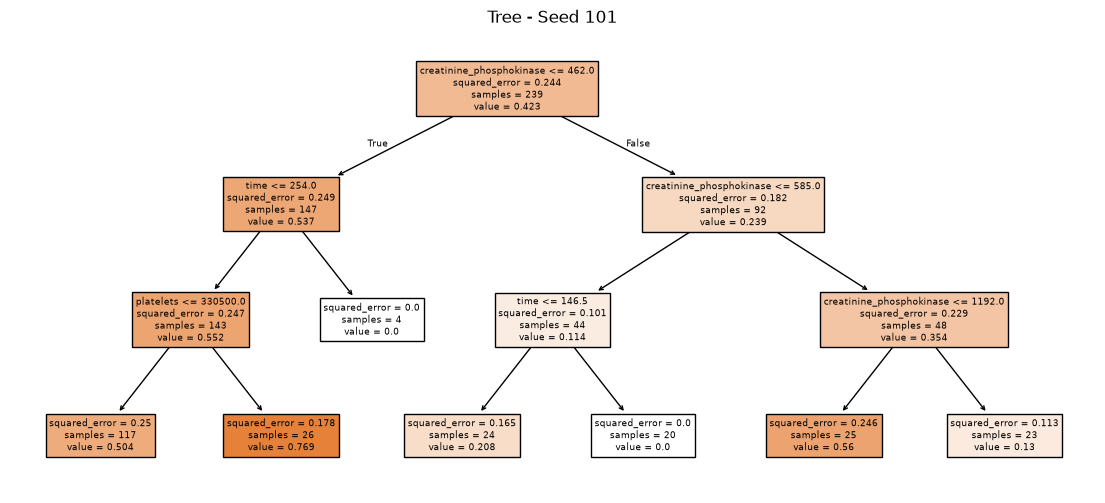

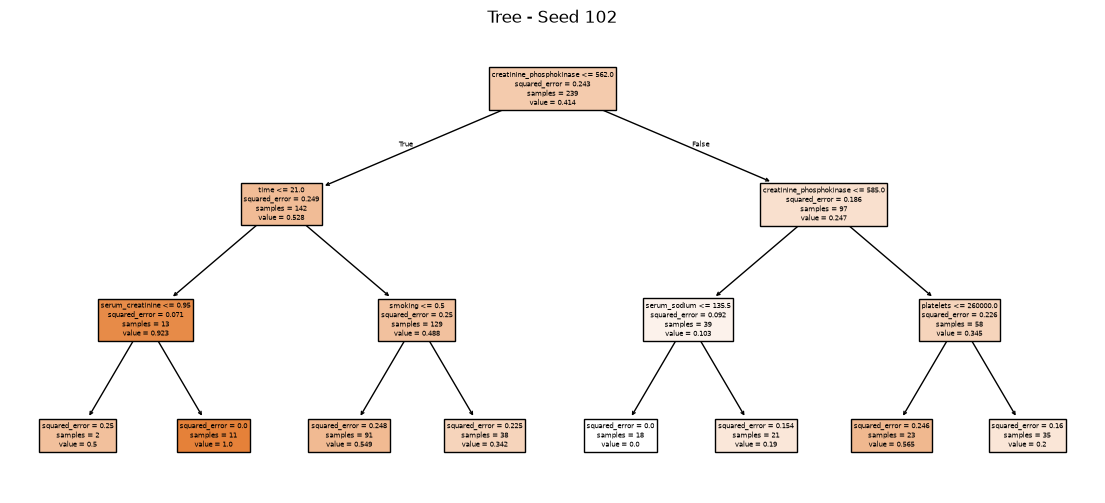

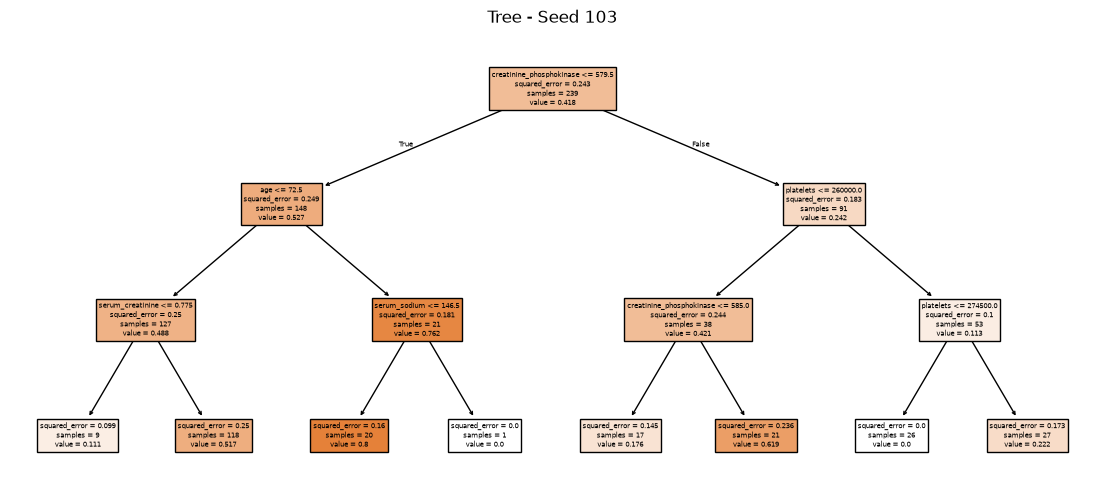

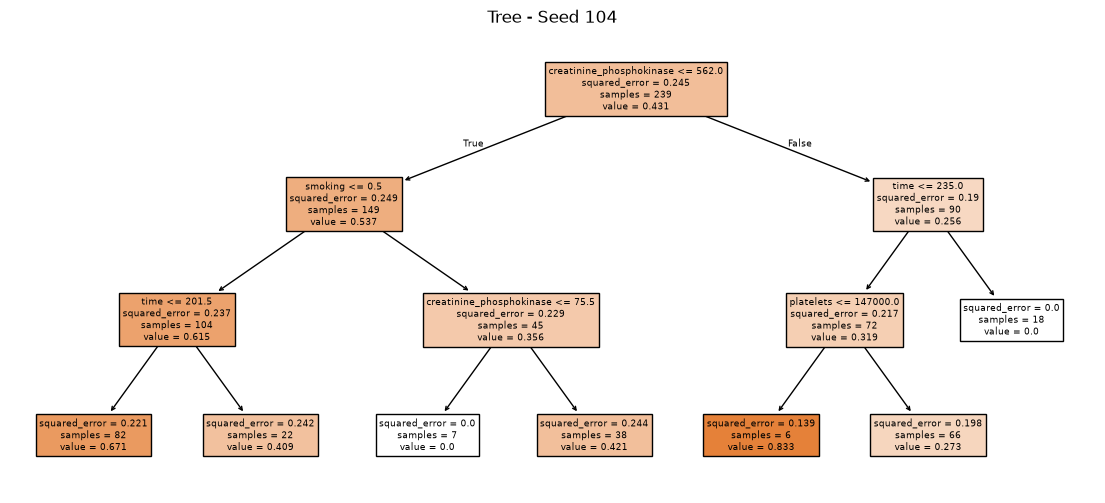

In [34]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(tree_model, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 100")
plt.show()

plt.figure(figsize=(14, 6))
plot_tree(tree_101, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 101")
plt.show()

plt.figure(figsize=(14, 6))
plot_tree(tree_102, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 102")
plt.show()
plt.figure(figsize=(14, 6))
plot_tree(tree_103, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 103")
plt.show()

plt.figure(figsize=(14, 6))
plot_tree(tree_104, feature_names=eval_x_raw.columns, filled=True)
plt.title("Tree - Seed 104")
plt.show()

In [36]:
# How different are the trees?
# The trees change a lot across seeds 100-104. They all start with
# creatinine_phosphokinase ( shifting from 462.0 to 579.5) but the the lower branches swap out
# different features (like smoking, time, age, platelets, and serum_creatinine) depending on the 
#split and test R-squared jumps from -0.0629 down to -0.3371.

# How different are the linear model coefficients?
# The linear model coefficients are much more stable because linear regression averages across all training rows at once. 
#Main features keep the same sign and stay very close across all 5 seeds
# like creatinine_phosphokinase stays around -0.0001,
# Only weak features near zero like diabetes and DEATH_EVENT flip signs slightly.




4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

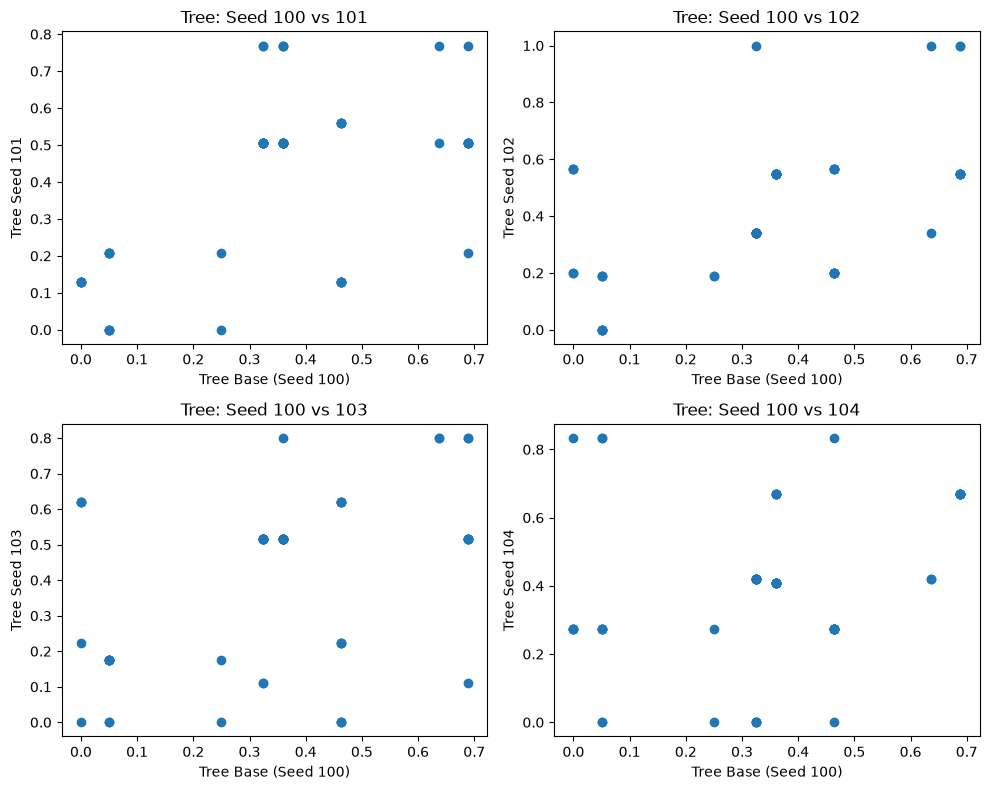

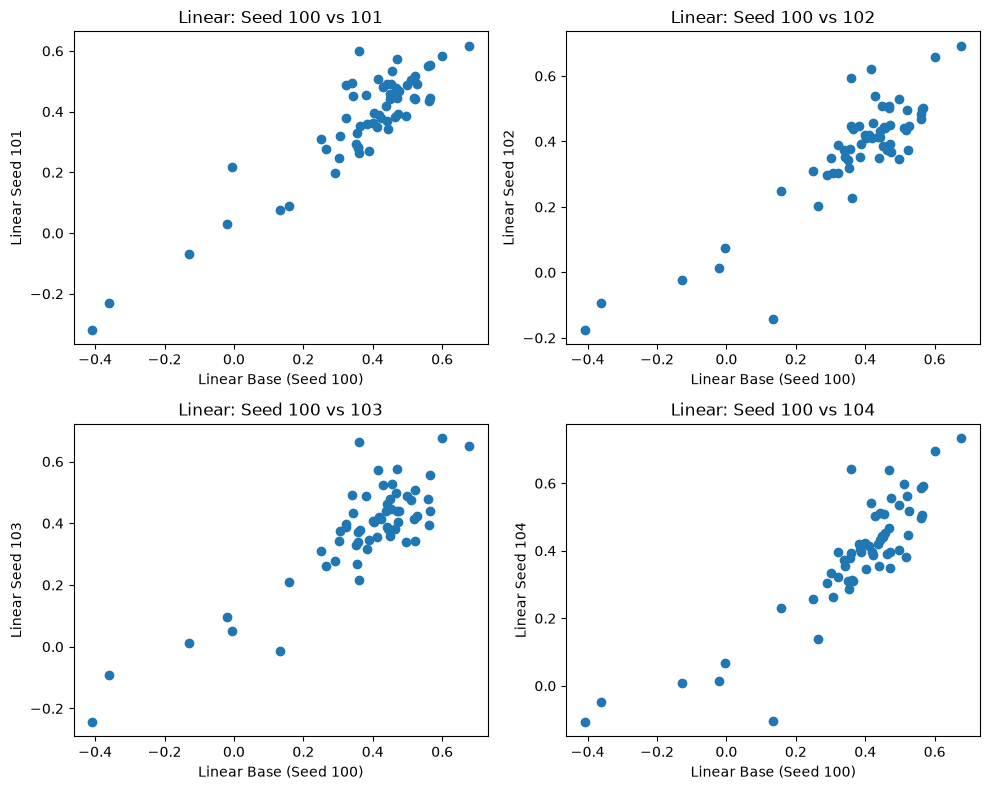

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.scatter(tree_preds_base, tree_preds_101)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 101")
plt.title("Tree: Seed 100 vs 101")

plt.subplot(2, 2, 2)
plt.scatter(tree_preds_base, tree_preds_102)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 102")
plt.title("Tree: Seed 100 vs 102")

plt.subplot(2, 2, 3)
plt.scatter(tree_preds_base, tree_preds_103)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 103")
plt.title("Tree: Seed 100 vs 103")

plt.subplot(2, 2, 4)
plt.scatter(tree_preds_base, tree_preds_104)
plt.xlabel("Tree Base (Seed 100)")
plt.ylabel("Tree Seed 104")
plt.title("Tree: Seed 100 vs 104")

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.scatter(lin_preds_base, lin_preds_101)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 101")
plt.title("Linear: Seed 100 vs 101")

plt.subplot(2, 2, 2)
plt.scatter(lin_preds_base, lin_preds_102)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 102")
plt.title("Linear: Seed 100 vs 102")

plt.subplot(2, 2, 3)
plt.scatter(lin_preds_base, lin_preds_103)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 103")
plt.title("Linear: Seed 100 vs 103")

plt.subplot(2, 2, 4)
plt.scatter(lin_preds_base, lin_preds_104)
plt.xlabel("Linear Base (Seed 100)")
plt.ylabel("Linear Seed 104")
plt.title("Linear: Seed 100 vs 104")

plt.tight_layout()
plt.show()



In [41]:
# Do they appear reasonably similar?
# The linear model predictions look pretty similar across seeds since the points follow an upward diagonal
# trend. The decision tree scatterplots are way more spread out and scattered

In [43]:
#use the EDA slide dont know if it right for correlation though
tree_df = pd.DataFrame({
    "Base_100": tree_preds_base,
    "Seed_101": tree_preds_101,
    "Seed_102": tree_preds_102,
    "Seed_103": tree_preds_103,
    "Seed_104": tree_preds_104
})
print("Tree Correlations:")
print(tree_df.corr().round(4))

lin_df = pd.DataFrame({
    "Base_100": lin_preds_base,
    "Seed_101": lin_preds_101,
    "Seed_102": lin_preds_102,
    "Seed_103": lin_preds_103,
    "Seed_104": lin_preds_104
})
print("\nLinear Model Correlations:")
print(lin_df.corr().round(4))

Tree Correlations:
          Base_100  Seed_101  Seed_102  Seed_103  Seed_104
Base_100    1.0000    0.5301    0.5477    0.4039    0.3119
Seed_101    0.5301    1.0000    0.5185    0.4791    0.2284
Seed_102    0.5477    0.5185    1.0000    0.7262    0.3811
Seed_103    0.4039    0.4791    0.7262    1.0000    0.3420
Seed_104    0.3119    0.2284    0.3811    0.3420    1.0000

Linear Model Correlations:
          Base_100  Seed_101  Seed_102  Seed_103  Seed_104
Base_100    1.0000    0.9114    0.8823    0.8727    0.8774
Seed_101    0.9114    1.0000    0.8933    0.9463    0.9007
Seed_102    0.8823    0.8933    1.0000    0.9573    0.9398
Seed_103    0.8727    0.9463    0.9573    1.0000    0.9253
Seed_104    0.8774    0.9007    0.9398    0.9253    1.0000


In [44]:
# Are they highly correlated or not?
# The linear model predictions are correlated with the base model across all seeds
# like 0.9114, 0.8823, 0.8727, and 0.8774 which shows that the linear model has a very similar predictions
# even when the train-test split changes.The decision tree correlations with the base tree are much lower like 0.5301, 0.5477, 0.4039, and 0.3119,
# showing that the tree predictions are much less consistent when it has different splits.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]